In [ ]:
#Method 1
import pandas as pd
file_path = "/content/SkyBridge_Airline_Data (1).xlsx"
df = pd.read_excel(file_path, sheet_name="Unclean_Data")
df.head()

,Date,Flight_ID,Route,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
0,2026-01-01,SB-001,Delhi-Mumbai,143.0,5650.0,26.0,133.0,429.0,60600.0,2.0,3.9,NaN
1,2026-01-02,SB-002,Delhi-Bengaluru,158.0,7200.0,18.0,163.0,528.0,67600.0,3.0,4.1,6.3
2,2026-01-03,SB-003,Delhi-Bengaluru,178.0,6200.0,6.0,169.0,585.0,71700.0,3.0,4.4,5.3
3,2026-01-04,SB-004,Delhi-Mumbai,145.0,5800.0,9.0,131.0,433.0,61400.0,4.0,4.1,4.0
4,2026-01-05,SB-005,Delhi-Mumbai,159.0,5450.0,18.0,130.0,428.0,70000.0,2.0,4.0,8.7


In [ ]:
# Method 2
raw = pd.read_excel("/content/SkyBridge_Airline_Data (1).xlsx", sheet_name="Unclean_Data")
# The 9 numeric columns we will study
num_cols = ["Passengers", "Ticket_Price", "Delay_Minutes", "Flight_Duration_Min", "Fuel_Cost", "Ancillary_Revenue", "Baggage_Complaints", "Customer_Rating", "Crew_Overtime_Hours"]
print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (120, 12)


,Date,Flight_ID,Route,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
0,2026-01-01,SB-001,Delhi-Mumbai,143.0,5650.0,26.0,133.0,429.0,60600.0,2.0,3.9,NaN
1,2026-01-02,SB-002,Delhi-Bengaluru,158.0,7200.0,18.0,163.0,528.0,67600.0,3.0,4.1,6.3
2,2026-01-03,SB-003,Delhi-Bengaluru,178.0,6200.0,6.0,169.0,585.0,71700.0,3.0,4.4,5.3
3,2026-01-04,SB-004,Delhi-Mumbai,145.0,5800.0,9.0,131.0,433.0,61400.0,4.0,4.1,4.0
4,2026-01-05,SB-005,Delhi-Mumbai,159.0,5450.0,18.0,130.0,428.0,70000.0,2.0,4.0,8.7


In [ ]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Date                 120 non-null    datetime64[ns]
 1   Flight_ID            120 non-null    object        
 2   Route                116 non-null    object        
 3   Passengers           115 non-null    float64       
 4   Ticket_Price         113 non-null    float64       
 5   Delay_Minutes        114 non-null    float64       
 6   Flight_Duration_Min  116 non-null    float64       
 7   Fuel_Cost            114 non-null    float64       
 8   Ancillary_Revenue    114 non-null    float64       
 9   Baggage_Complaints   115 non-null    float64       
 10  Customer_Rating      113 non-null    float64       
 11  Crew_Overtime_Hours  112 non-null    float64       
dtypes: datetime64[ns](1), float64(9), object(2)
memory usage: 11.4+ KB


LECTURE TOPIC :unsual values in business dataset
find the missing blanks cells

In [ ]:
raw.isnull().sum()

,0
Date,0
Flight_ID,0
Route,4
Passengers,5
Ticket_Price,7
Delay_Minutes,6
Flight_Duration_Min,4
Fuel_Cost,6
Ancillary_Revenue,6
Baggage_Complaints,5


In [ ]:
total_blank = raw.isnull().sum().sum()

print("Blank cells :", total_blank)
print("Blank %     :", round(total_blank / raw.size * 100, 1), "%")
print("Rows with at least one blank:", raw.isnull().any(axis=1).sum(), "out of", len(raw))

Blank cells : 58
Blank %     : 4.0 %
Rows with at least one blank: 48 out of 120


#Before heatmap : red = blank cell, grey = filled cell


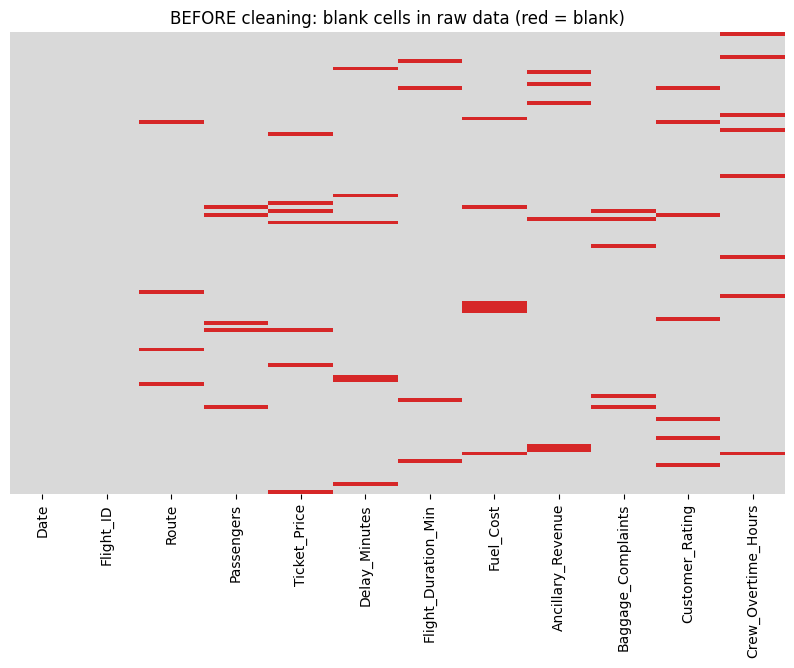

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

colors = ListedColormap(["#d9d9d9", "#d62728"])

plt.figure(figsize=(10, 6))
sns.heatmap(raw.isnull(), cmap=colors, cbar=False, yticklabels=False)

plt.title("BEFORE cleaning: blank cells in raw data (red = blank)")
plt.show()

lecture topics : unsual values in business datasets

In [ ]:
raw[num_cols].describe().round(1)

,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,115.0,113.0,114.0,116.0,114.0,114.0,115.0,113.0,112.0
mean,155.0,6374.3,19.4,157.2,511.2,59615.8,3.1,4.2,6.5
std,13.6,4836.7,35.9,30.0,78.0,11182.3,2.4,0.6,2.8
min,120.0,4800.0,-45.0,122.0,398.0,37900.0,0.0,3.5,2.8
25%,147.0,5550.0,9.0,132.0,433.0,54425.0,2.0,4.0,5.2
50%,155.0,5900.0,16.0,165.0,530.0,58800.0,3.0,4.1,6.1
75%,163.0,6300.0,23.8,170.0,563.8,64225.0,4.0,4.3,7.3
max,215.0,57000.0,380.0,410.0,980.0,148000.0,19.0,9.4,31.5


In [ ]:
# A big gap between mean and median is a warning sign

gap = pd.DataFrame({
    "Mean": raw[num_cols].mean(),
    "Median": raw[num_cols].median(),
})

gap["Gap %"] = (
    (gap["Mean"] - gap["Median"]) / gap["Median"] * 100
).round(1)

gap.round(1)

,Mean,Median,Gap %
Passengers,155.0,155.0,-0.0
Ticket_Price,6374.3,5900.0,8.0
Delay_Minutes,19.4,16.0,21.2
Flight_Duration_Min,157.2,165.0,-4.7
Fuel_Cost,511.2,530.0,-3.5
Ancillary_Revenue,59615.8,58800.0,1.4
Baggage_Complaints,3.1,3.0,3.5
Customer_Rating,4.2,4.1,1.8
Crew_Overtime_Hours,6.5,6.1,6.2


STEP 1 : MISSING VALUE : SETTING UP RULES FOR EACH VARIABLES

In [ ]:
rules = {
    "Passengers": (0, 180),  # aircraft has 180 seats
    "Ticket_Price": (1000, 20000),  # domestic low-cost fare in INR
    "Delay_Minutes": (0, 600),  # a delay cannot be negative
    "Flight_Duration_Min": (60, 240),  # domestic sector
    "Customer_Rating": (1, 5),  # rating scale 1 to 5
}

for col, (low, high) in rules.items():
    bad = raw[(raw[col] < low) | (raw[col] > high)]
    print(col, "-> impossible values:", len(bad))
    if len(bad) > 0:
        print(bad[["Date", "Flight_ID", col]].to_string(index=False))
    print()

Passengers -> impossible values: 1
      Date Flight_ID  Passengers
2026-02-07    SB-038       215.0

Ticket_Price -> impossible values: 1
      Date Flight_ID  Ticket_Price
2026-01-15    SB-015       57000.0

Delay_Minutes -> impossible values: 1
      Date Flight_ID  Delay_Minutes
2026-01-23    SB-023          -45.0

Flight_Duration_Min -> impossible values: 1
      Date Flight_ID  Flight_Duration_Min
2026-04-02    SB-092                410.0

Customer_Rating -> impossible values: 1
      Date Flight_ID  Customer_Rating
2026-03-18    SB-077              9.4



STEP 2 TIME SERIES PLOT (HOW MANY ARE MISSING )

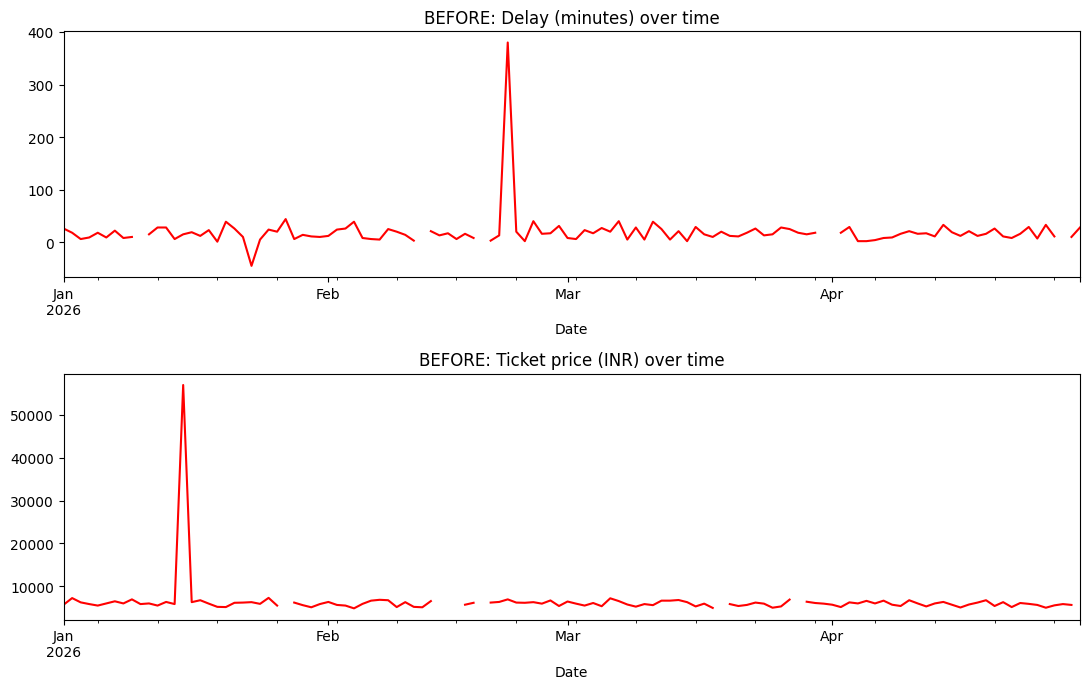

In [ ]:
ts_raw = raw.set_index("Date")

fig, axes = plt.subplots(2, 1, figsize=(11, 7))

ts_raw["Delay_Minutes"].plot(
    ax=axes[0], color="red", title="BEFORE: Delay (minutes) over time"
)
ts_raw["Ticket_Price"].plot(
    ax=axes[1], color="red", title="BEFORE: Ticket price (INR) over time"
)

plt.tight_layout()
plt.show()

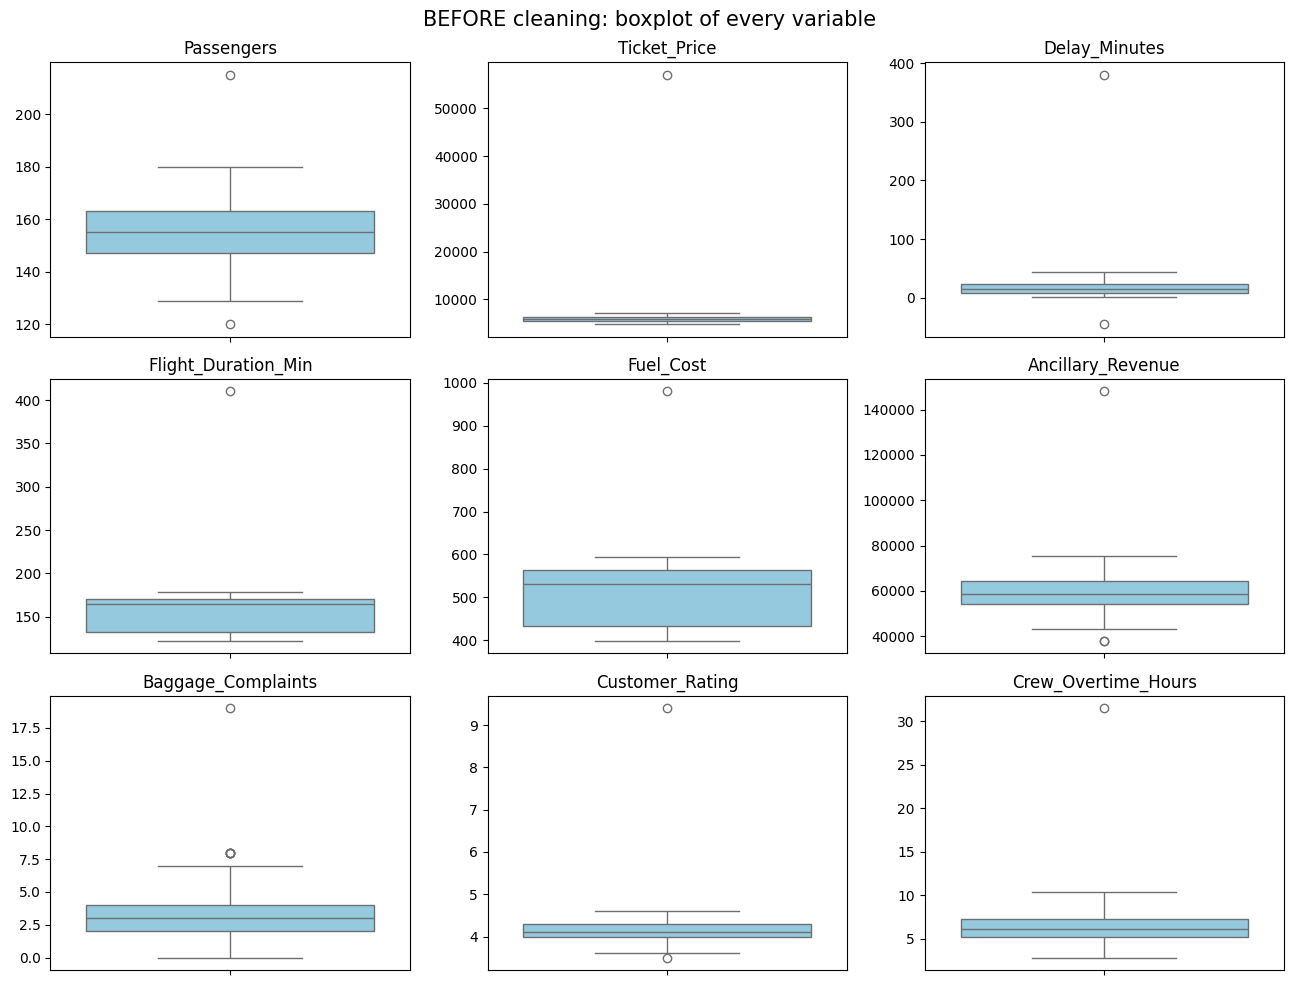

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

def show_boxplots(data, title):
    fig, axes = plt.subplots(3, 3, figsize=(13, 10))
    axes = axes.flatten()
    for i, col in enumerate(num_cols):
        sns.boxplot(y=data[col], ax=axes[i], color="skyblue")
        axes[i].set_title(col)
        axes[i].set_ylabel("")
    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

show_boxplots(raw, "BEFORE cleaning: boxplot of every variable")

step 3 retaining , removing and capping the data

In [ ]:
raw [raw["Delay_Minutes"]>100]

,Date,Flight_ID,Route,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
52,2026-02-22,SB-053,Delhi-Bengaluru,147.0,6900.0,380.0,173.0,980.0,62500.0,19.0,4.2,31.5


step 4 removing impossible values

In [ ]:
import numpy as np

# Create a copy
df = raw.copy()

# Find ratings below 1 or above 5
bad_values = (df["Customer_Rating"] < 1) | (df["Customer_Rating"] > 5)

# Count unusual ratings
print("Unusual ratings:", bad_values.sum())

# Replace unusual ratings with missing values
df.loc[bad_values, "Customer_Rating"] = np.nan

# Compare missing cells
print("Missing cells before:", raw.isnull().sum().sum())
print("Missing cells after:", df.isnull().sum().sum())

Unusual ratings: 1
Missing cells before: 58
Missing cells after: 59


Maximum before: 148000.0
Maximum after: 78925.0
Upper limit: 78925.0


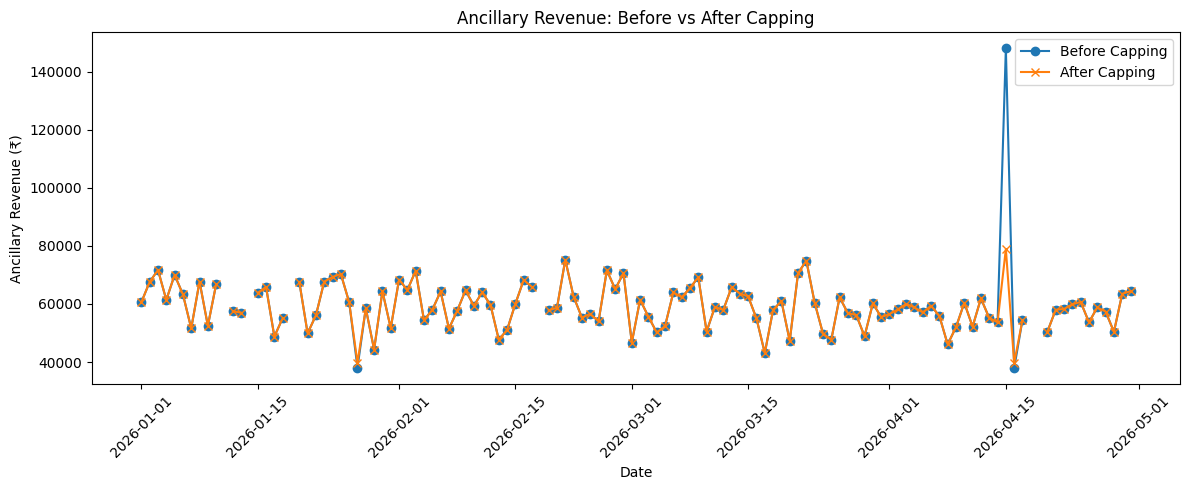

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Select the variable
col = "Ancillary_Revenue"

# Start with the original, uncapped data
before = raw[col].copy()

# Create a fresh dataset for capping
df_capped = raw.copy()

# Calculate Q1, Q3 and IQR using original data
Q1 = before.quantile(0.25)
Q3 = before.quantile(0.75)
IQR = Q3 - Q1

# Calculate the upper and lower limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Apply capping to the new dataset
df_capped[col] = before.clip(lower, upper)

# Print maximum values
print("Maximum before:", before.max())
print("Maximum after:", df_capped[col].max())
print("Upper limit:", upper)

# Plot before and after
plt.figure(figsize=(12, 5))

plt.plot(raw["Date"], before,
         label="Before Capping", marker="o")

plt.plot(raw["Date"], df_capped[col],
         label="After Capping", marker="x")

plt.title("Ancillary Revenue: Before vs After Capping")
plt.xlabel("Date")
plt.ylabel("Ancillary Revenue (₹)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

LECTURE 8
FLAG BY INTERQUARTILE RANGE

In [ ]:
# Examples we keep: 120 passengers on a quiet day, baggage complaints of 8, the fog-day values

df[(df["Passengers"] < 125) | (df["Baggage_Complaints"] >= 8) | (df["Delay_Minutes"] > 100)][
    ["Date", "Passengers", "Delay_Minutes", "Baggage_Complaints"]
]

,Date,Passengers,Delay_Minutes,Baggage_Complaints
26,2026-01-27,120.0,44.0,2.0
33,2026-02-03,169.0,26.0,8.0
52,2026-02-22,147.0,380.0,19.0
63,2026-03-05,167.0,27.0,8.0
76,2026-03-18,157.0,10.0,8.0
104,2026-04-15,143.0,19.0,8.0
109,2026-04-20,143.0,26.0,8.0


METHOD 1 : DROP NULL VALUES

In [ ]:
# Method 1: Remove rows containing missing values
df_drop = df.dropna()

# Show descriptive statistics before removing missing values
print("DESCRIPTIVE STATISTICS BEFORE dropna()")
display(df.describe().round(2))

# Show descriptive statistics after removing missing values
print("DESCRIPTIVE STATISTICS AFTER dropna()")
display(df_drop.describe().round(2))

# Compare the number of rows
print("Rows before:", len(df))
print("Rows after :", len(df_drop))

# Calculate percentage of data lost
print("Data lost:", round((1 - len(df_drop) / len(df)) * 100, 1), "%")

# Check missing values in each column after dropna()
print("Missing values after dropna():")
print(df_drop.isnull().sum())

# Count all missing cells in the dataset
print("Total blank cells:", df_drop.isnull().sum().sum())

DESCRIPTIVE STATISTICS BEFORE dropna()


,Date,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,120,115.00,113.00,114.00,116.00,114.00,114.00,115.00,112.00,112.00
mean,2026-03-01 12:00:00,154.96,6374.34,19.39,157.19,511.22,59615.79,3.10,4.13,6.48
min,2026-01-01 00:00:00,120.00,4800.00,-45.00,122.00,398.00,37900.00,0.00,3.50,2.80
25%,2026-01-30 18:00:00,147.00,5550.00,9.00,132.00,433.00,54425.00,2.00,4.00,5.20
50%,2026-03-01 12:00:00,155.00,5900.00,16.00,165.00,530.00,58800.00,3.00,4.10,6.10
75%,2026-03-31 06:00:00,163.00,6300.00,23.75,170.00,563.75,64225.00,4.00,4.30,7.30
max,2026-04-30 00:00:00,215.00,57000.00,380.00,410.00,980.00,148000.00,19.00,4.60,31.50
std,NaN,13.61,4836.71,35.89,30.01,78.03,11182.33,2.41,0.26,2.81


DESCRIPTIVE STATISTICS AFTER dropna()


,Date,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,71,71.00,71.00,71.00,71.00,71.00,71.00,71.00,71.00,71.00
mean,2026-02-27 22:18:35.492957696,155.49,5965.49,22.42,154.34,513.34,60826.76,3.15,4.13,6.74
min,2026-01-02 00:00:00,129.00,4800.00,2.00,122.00,398.00,44300.00,0.00,3.60,3.90
25%,2026-01-31 12:00:00,148.50,5550.00,10.00,132.00,433.00,55150.00,2.00,4.00,5.15
50%,2026-02-27 00:00:00,155.00,5950.00,17.00,165.00,530.00,59400.00,3.00,4.10,6.30
75%,2026-03-28 00:00:00,161.50,6300.00,24.50,169.00,563.50,64350.00,4.00,4.30,7.50
max,2026-04-29 00:00:00,180.00,7250.00,380.00,179.00,980.00,148000.00,19.00,4.60,31.50
std,NaN,11.46,574.99,44.10,18.82,85.26,12653.82,2.74,0.23,3.35


Rows before: 120
Rows after : 71
Data lost: 40.8 %
Missing values after dropna():
Date                   0
Flight_ID              0
Route                  0
Passengers             0
Ticket_Price           0
Delay_Minutes          0
Flight_Duration_Min    0
Fuel_Cost              0
Ancillary_Revenue      0
Baggage_Complaints     0
Customer_Rating        0
Crew_Overtime_Hours    0
dtype: int64
Total blank cells: 0


METHOD 2: SUBSTITUTE WITH MEAN

In [ ]:
# Create a copy of the original dataset
df_mean = df.copy()

# Display descriptive statistics BEFORE filling missing values
print("DESCRIPTIVE STATISTICS BEFORE IMPUTATION")
display(df.describe().round(2))

# Fill missing values in numeric columns using the mean
df_mean[num_cols] = df_mean[num_cols].fillna(df_mean[num_cols].mean())

# Fill missing Route values using the most common route (mode)
df_mean["Route"] = df_mean["Route"].fillna(df_mean["Route"].mode()[0])

# Display descriptive statistics AFTER filling missing values
print("DESCRIPTIVE STATISTICS AFTER MEAN AND MODE IMPUTATION")
display(df_mean.describe().round(2))

# Compare the number of rows before and after
print("Rows before:", len(df))
print("Rows after :", len(df_mean))

# Count missing cells remaining after imputation
print("Blanks left:", df_mean.isnull().sum().sum())

DESCRIPTIVE STATISTICS BEFORE IMPUTATION


,Date,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,120,115.00,113.00,114.00,116.00,114.00,114.00,115.00,112.00,112.00
mean,2026-03-01 12:00:00,154.96,6374.34,19.39,157.19,511.22,59615.79,3.10,4.13,6.48
min,2026-01-01 00:00:00,120.00,4800.00,-45.00,122.00,398.00,37900.00,0.00,3.50,2.80
25%,2026-01-30 18:00:00,147.00,5550.00,9.00,132.00,433.00,54425.00,2.00,4.00,5.20
50%,2026-03-01 12:00:00,155.00,5900.00,16.00,165.00,530.00,58800.00,3.00,4.10,6.10
75%,2026-03-31 06:00:00,163.00,6300.00,23.75,170.00,563.75,64225.00,4.00,4.30,7.30
max,2026-04-30 00:00:00,215.00,57000.00,380.00,410.00,980.00,148000.00,19.00,4.60,31.50
std,NaN,13.61,4836.71,35.89,30.01,78.03,11182.33,2.41,0.26,2.81


DESCRIPTIVE STATISTICS AFTER MEAN AND MODE IMPUTATION


,Date,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,120,120.00,120.00,120.00,120.00,120.00,120.00,120.00,120.00,120.00
mean,2026-03-01 12:00:00,154.96,6374.34,19.39,157.19,511.22,59615.79,3.10,4.13,6.48
min,2026-01-01 00:00:00,120.00,4800.00,-45.00,122.00,398.00,37900.00,0.00,3.50,2.80
25%,2026-01-30 18:00:00,147.00,5587.50,9.75,132.75,433.75,54875.00,2.00,4.00,5.28
50%,2026-03-01 12:00:00,154.96,5950.00,16.00,165.00,529.50,59400.00,3.00,4.13,6.30
75%,2026-03-31 06:00:00,162.25,6356.08,23.00,169.25,563.00,64000.00,4.00,4.30,7.22
max,2026-04-30 00:00:00,215.00,57000.00,380.00,410.00,980.00,148000.00,19.00,4.60,31.50
std,NaN,13.32,4692.30,34.97,29.50,76.04,10896.78,2.36,0.25,2.71


Rows before: 120
Rows after : 120
Blanks left: 0


METHOD 3 : SUBSTITUTE WITH MODE

In [ ]:
df_mode = df.copy()

for col in df_mode.columns:
    df_mode[col] = df_mode[col].fillna(df_mode[col].mode()[0])

print("Blanks left:", df_mode.isnull().sum().sum())

Blanks left: 0


METHOD 3:SUBSTITUTE WITH THE MEDIAN

In [ ]:
df_median = df.copy()

df_median[num_cols] = df_median[num_cols].fillna(df_median[num_cols].median())

# Route is text, so use the most common route
df_median["Route"] = df_median["Route"].fillna(df_median["Route"].mode()[0])

print("Blanks left:", df_median.isnull().sum().sum())

Blanks left: 0


In [ ]:
# Descriptive Statistics

# Display descriptive statistics for the dataset
print("DESCRIPTIVE STATISTICS")

display(df.describe().round(2))

# Check data types and non-null values
print("DATASET INFORMATION")
df.info()

# Check missing values in each column
print("MISSING VALUES")
print(df.isnull().sum())

# Calculate mean, median, and mode
print("MEAN")
display(df.mean(numeric_only=True).round(2))

print("MEDIAN")
display(df.median(numeric_only=True).round(2))

print("MODE")
display(df.mode().head(1))

DESCRIPTIVE STATISTICS


,Date,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,120,115.00,113.00,114.00,116.00,114.00,114.00,115.00,112.00,112.00
mean,2026-03-01 12:00:00,154.96,6374.34,19.39,157.19,511.22,59615.79,3.10,4.13,6.48
min,2026-01-01 00:00:00,120.00,4800.00,-45.00,122.00,398.00,37900.00,0.00,3.50,2.80
25%,2026-01-30 18:00:00,147.00,5550.00,9.00,132.00,433.00,54425.00,2.00,4.00,5.20
50%,2026-03-01 12:00:00,155.00,5900.00,16.00,165.00,530.00,58800.00,3.00,4.10,6.10
75%,2026-03-31 06:00:00,163.00,6300.00,23.75,170.00,563.75,64225.00,4.00,4.30,7.30
max,2026-04-30 00:00:00,215.00,57000.00,380.00,410.00,980.00,148000.00,19.00,4.60,31.50
std,NaN,13.61,4836.71,35.89,30.01,78.03,11182.33,2.41,0.26,2.81


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Date                 120 non-null    datetime64[ns]
 1   Flight_ID            120 non-null    object        
 2   Route                116 non-null    object        
 3   Passengers           115 non-null    float64       
 4   Ticket_Price         113 non-null    float64       
 5   Delay_Minutes        114 non-null    float64       
 6   Flight_Duration_Min  116 non-null    float64       
 7   Fuel_Cost            114 non-null    float64       
 8   Ancillary_Revenue    114 non-null    float64       
 9   Baggage_Complaints   115 non-null    float64       
 10  Customer_Rating      112 non-null    float64       
 11  Crew_Overtime_Hours  112 non-null    float64       
dtypes: datetime64[ns](1), float64(9), object(2)
memory usage: 11.4+ KB
MISSI

,0
Passengers,154.96
Ticket_Price,6374.34
Delay_Minutes,19.39
Flight_Duration_Min,157.19
Fuel_Cost,511.22
Ancillary_Revenue,59615.79
Baggage_Complaints,3.10
Customer_Rating,4.13
Crew_Overtime_Hours,6.48


MEDIAN


,0
Passengers,155.0
Ticket_Price,5900.0
Delay_Minutes,16.0
Flight_Duration_Min,165.0
Fuel_Cost,530.0
Ancillary_Revenue,58800.0
Baggage_Complaints,3.0
Customer_Rating,4.1
Crew_Overtime_Hours,6.1


MODE


,Date,Flight_ID,Route,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
0,2026-01-01,SB-001,Delhi-Bengaluru,159.0,5800.0,6.0,129.0,530.0,58000.0,2.0,4.1,4.8


#HEAT PLOTS AFTER TREATMENT

In [ ]:
# Descriptive Statistics

# Display descriptive statistics for the dataset
print("DESCRIPTIVE STATISTICS")

display(df.describe().round(2))

# Check data types and non-null values
print("DATASET INFORMATION")
df.info()

# Check missing values in each column
print("MISSING VALUES")
print(df.isnull().sum())

# Calculate mean, median, and mode
print("MEAN")
display(df.mean(numeric_only=True).round(2))

print("MEDIAN")
display(df.median(numeric_only=True).round(2))

print("MODE")
display(df.mode().head(1))

DESCRIPTIVE STATISTICS


,Date,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
count,120,115.00,113.00,114.00,116.00,114.00,114.00,115.00,112.00,112.00
mean,2026-03-01 12:00:00,154.96,6374.34,19.39,157.19,511.22,59615.79,3.10,4.13,6.48
min,2026-01-01 00:00:00,120.00,4800.00,-45.00,122.00,398.00,37900.00,0.00,3.50,2.80
25%,2026-01-30 18:00:00,147.00,5550.00,9.00,132.00,433.00,54425.00,2.00,4.00,5.20
50%,2026-03-01 12:00:00,155.00,5900.00,16.00,165.00,530.00,58800.00,3.00,4.10,6.10
75%,2026-03-31 06:00:00,163.00,6300.00,23.75,170.00,563.75,64225.00,4.00,4.30,7.30
max,2026-04-30 00:00:00,215.00,57000.00,380.00,410.00,980.00,148000.00,19.00,4.60,31.50
std,NaN,13.61,4836.71,35.89,30.01,78.03,11182.33,2.41,0.26,2.81


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Date                 120 non-null    datetime64[ns]
 1   Flight_ID            120 non-null    object        
 2   Route                116 non-null    object        
 3   Passengers           115 non-null    float64       
 4   Ticket_Price         113 non-null    float64       
 5   Delay_Minutes        114 non-null    float64       
 6   Flight_Duration_Min  116 non-null    float64       
 7   Fuel_Cost            114 non-null    float64       
 8   Ancillary_Revenue    114 non-null    float64       
 9   Baggage_Complaints   115 non-null    float64       
 10  Customer_Rating      112 non-null    float64       
 11  Crew_Overtime_Hours  112 non-null    float64       
dtypes: datetime64[ns](1), float64(9), object(2)
memory usage: 11.4+ KB
MISSI

,0
Passengers,154.96
Ticket_Price,6374.34
Delay_Minutes,19.39
Flight_Duration_Min,157.19
Fuel_Cost,511.22
Ancillary_Revenue,59615.79
Baggage_Complaints,3.10
Customer_Rating,4.13
Crew_Overtime_Hours,6.48


MEDIAN


,0
Passengers,155.0
Ticket_Price,5900.0
Delay_Minutes,16.0
Flight_Duration_Min,165.0
Fuel_Cost,530.0
Ancillary_Revenue,58800.0
Baggage_Complaints,3.0
Customer_Rating,4.1
Crew_Overtime_Hours,6.1


MODE


,Date,Flight_ID,Route,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
0,2026-01-01,SB-001,Delhi-Bengaluru,159.0,5800.0,6.0,129.0,530.0,58000.0,2.0,4.1,4.8


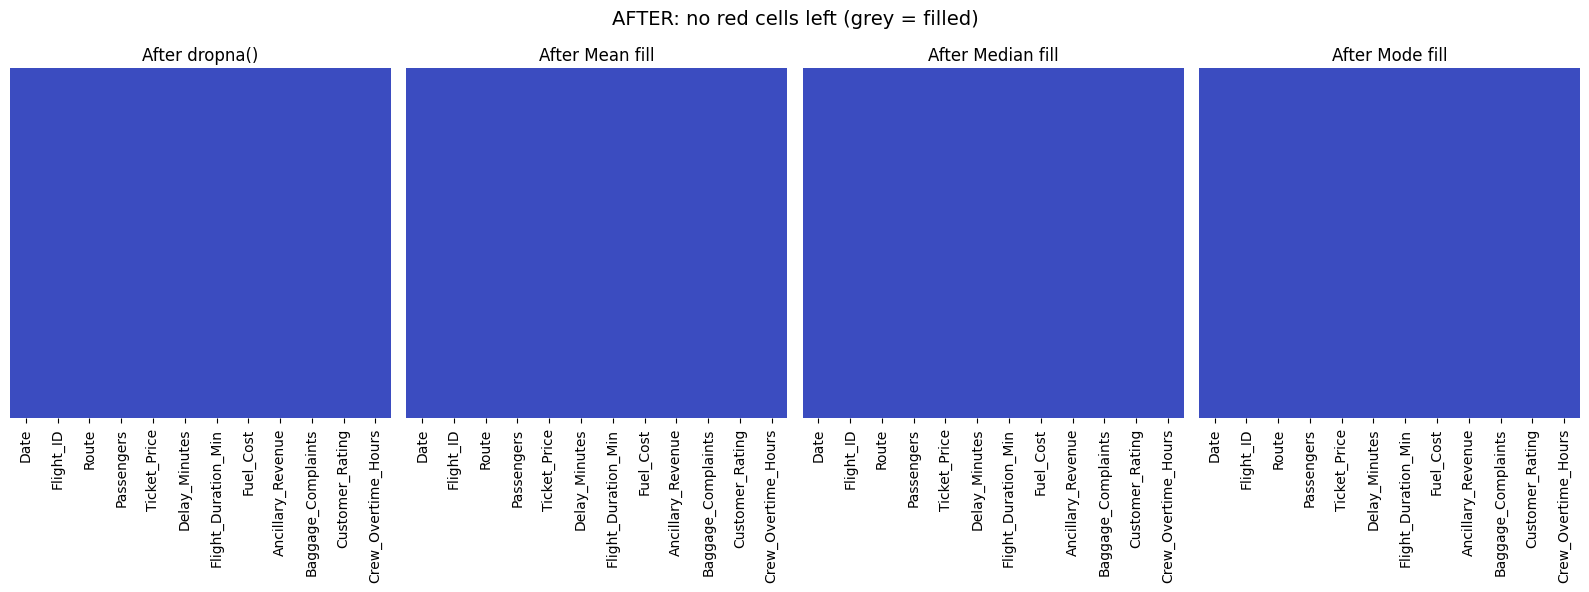

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 4, figsize=(16, 6))

sns.heatmap(
    df_drop.isnull(),
    cmap="coolwarm",
    cbar=False,
    yticklabels=False,
    ax=axes[0]
)
axes[0].set_title("After dropna()")

sns.heatmap(
    df_mean.isnull(),
    cmap="coolwarm",
    cbar=False,
    yticklabels=False,
    ax=axes[1]
)
axes[1].set_title("After Mean fill")

sns.heatmap(
    df_median.isnull(),
    cmap="coolwarm",
    cbar=False,
    yticklabels=False,
    ax=axes[2]
)
axes[2].set_title("After Median fill")

sns.heatmap(
    df_mode.isnull(),
    cmap="coolwarm",
    cbar=False,
    yticklabels=False,
    ax=axes[3]
)
axes[3].set_title("After Mode fill")

plt.suptitle(
    "AFTER: no red cells left (grey = filled)",
    fontsize=14
)
plt.tight_layout()
plt.show()

# BOXPLOT AFTER IMPUTATION

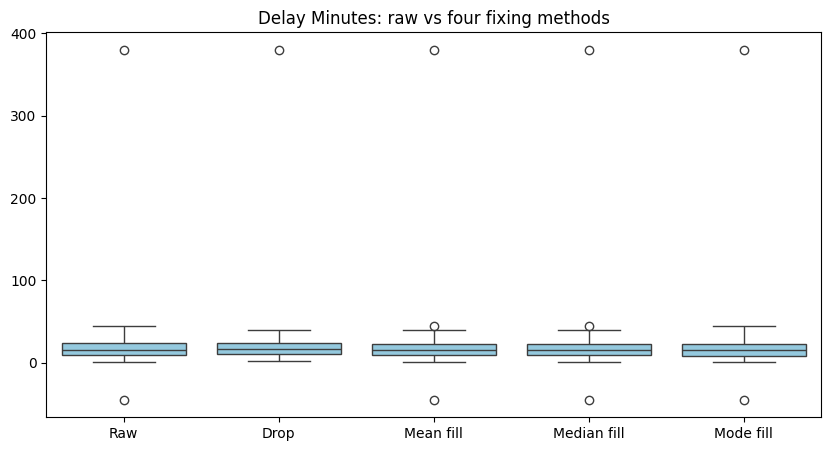

52     380.0
26      44.0
65      40.0
55      40.0
19      39.0
34      39.0
69      39.0
115     33.0
103     33.0
58      31.0
Name: Delay_Minutes, dtype: float64


In [ ]:
# Boxplot of Delay_Minutes: raw versus the four methods

delay_compare = pd.DataFrame({
    "Raw": raw["Delay_Minutes"],
    "Drop": df_drop["Delay_Minutes"],
    "Mean fill": df_mean["Delay_Minutes"],
    "Median fill": df_median["Delay_Minutes"],
    "Mode fill": df_mode["Delay_Minutes"]
})

plt.figure(figsize=(10, 5))
sns.boxplot(data=delay_compare, color="skyblue")
plt.title("Delay Minutes: raw vs four fixing methods")
plt.show()

# Check the largest delay values
print(
    raw["Delay_Minutes"]
    .sort_values(ascending=False)
    .head(10)
)

#DESCRIPTION OF CLEANING DATA

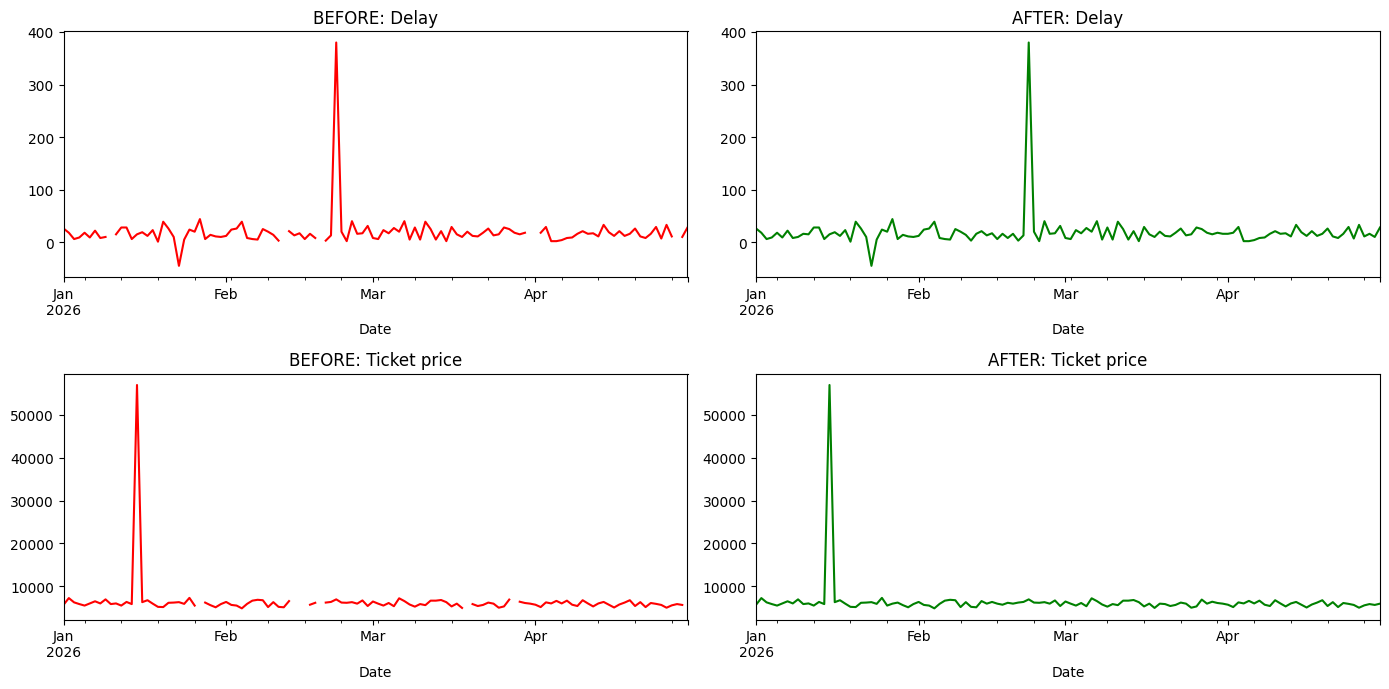

In [ ]:
# BEFORE vs AFTER: time series

# Define 'final' using one of your cleaned datasets (e.g., df_median)
final = df_median
ts_final = final.set_index("Date")
ts_raw = raw.set_index("Date")

fig, axes = plt.subplots(2, 2, figsize=(14, 7))

ts_raw["Delay_Minutes"].plot(
    ax=axes[0, 0],
    color="red",
    title="BEFORE: Delay"
)

ts_final["Delay_Minutes"].plot(
    ax=axes[0, 1],
    color="green",
    title="AFTER: Delay"
)

ts_raw["Ticket_Price"].plot(
    ax=axes[1, 0],
    color="red",
    title="BEFORE: Ticket price"
)

ts_final["Ticket_Price"].plot(
    ax=axes[1, 1],
    color="green",
    title="AFTER: Ticket price"
)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_excel("Zepto_Orders_Data (1).xlsx", sheet_name="Orders")

print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

Rows: 1200 | Columns: 14


,Order_ID,Order_Date,Time_Slot,State,City,Category,Customer_Type,Weather,Distance_KM,Basket_Size,Order_Value,Discount_Pct,Delivery_Time_Min,Customer_Rating
0,ZP-0001,2026-07-01,Afternoon,Haryana,Gurugram,Snacks & Drinks,Pass Member,Clear,1.1,7,755,18,9,4.9
1,ZP-0002,2026-07-01,Evening,Tamil Nadu,Chennai,Household Items,Pass Member,Clear,1.9,5,835,0,8,5.0
2,ZP-0003,2026-07-01,Afternoon,NCT of Delhi,Delhi,Dairy & Bread,Pass Member,Clear,0.3,5,605,20,9,4.7
3,ZP-0004,2026-07-01,Late Night,Uttar Pradesh,Noida,Snacks & Drinks,Pass Member,Clear,3.7,5,420,20,19,4.5
4,ZP-0005,2026-07-01,Evening,Kerala,Kochi,Dairy & Bread,New User,Clear,0.5,10,670,39,8,5.0


#Descriptive Statistics

In [ ]:
#Number of orderin a particualar state
df["State"].value_counts()

,count
State,
Karnataka,223
NCT of Delhi,188
Maharashtra,182
Telangana,113
Haryana,107
Tamil Nadu,107
Uttar Pradesh,94
Gujarat,55
West Bengal,54


In [ ]:
# Step 3 | Prepare helper columns

df["Week"] = df["Order_Date"].dt.isocalendar().week.astype(int)
df["Weekday"] = df["Order_Date"].dt.day_name()
df["Within_10_Min"] = df["Delivery_Time_Min"] <= 10  # True if we kept the promise

# Fixed orders so charts always show groups in a sensible order
slot_order = ["Morning", "Afternoon", "Evening", "Late Night"]
type_order = ["New User", "Regular", "Pass Member"]

df[["Order_Date", "Week", "Weekday", "Within_10_Min"]].head()

,Order_Date,Week,Weekday,Within_10_Min
0,2026-07-01,27,Wednesday,True
1,2026-07-01,27,Wednesday,True
2,2026-07-01,27,Wednesday,True
3,2026-07-01,27,Wednesday,False
4,2026-07-01,27,Wednesday,True


#Matplotlib- How long does it take the delivery take and how many are inside the promise

In [ ]:
import matplotlib.pyplot as plt


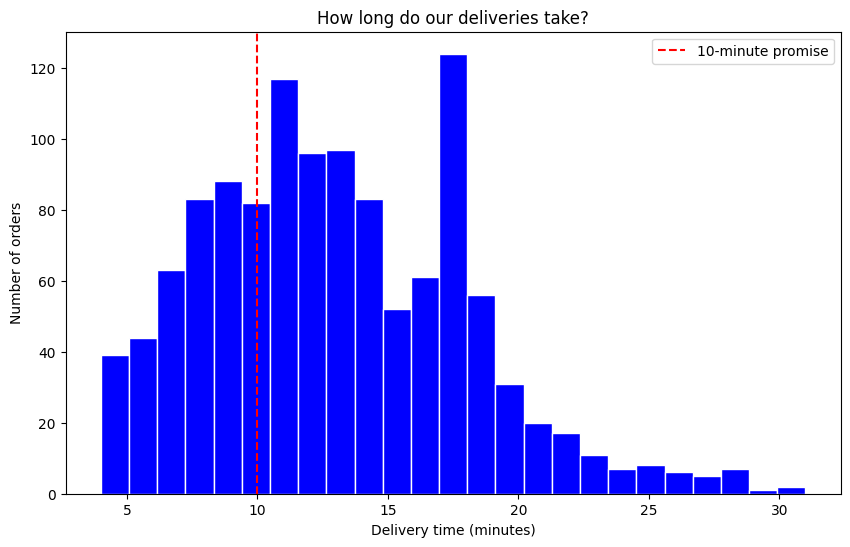

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Ensure delivery time is numeric
df["Delivery_Time_Min"] = pd.to_numeric(
    df["Delivery_Time_Min"], errors="coerce"
)

# Create histogram
plt.figure(figsize=(10, 6))

plt.hist(df["Delivery_Time_Min"].dropna(),
         bins=25, color="blue", edgecolor="white")

plt.axvline(10, color="red", linestyle="--",
            label="10-minute promise")

plt.title("How long do our deliveries take?")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Number of orders")
plt.legend()
plt.show()

#which product category bring the most sale


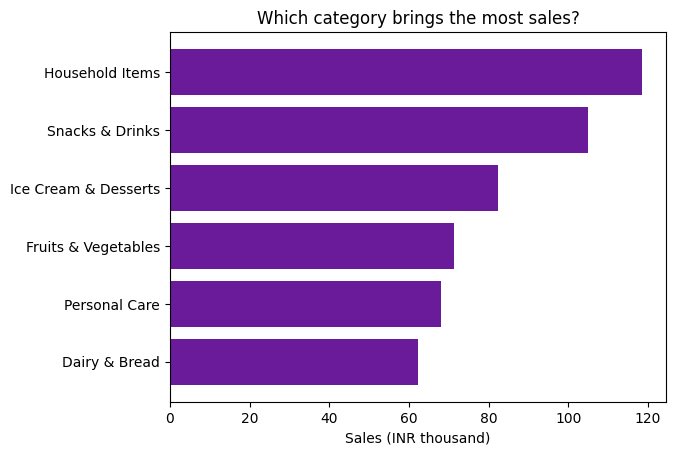

In [ ]:
# Calculate total sales category-wise
category_sales = df.groupby("Category")["Order_Value"].sum().sort_values()

# Create bar chart
plt.barh(category_sales.index, category_sales.values / 1000, color="#6A1B9A")

# Add chart title
plt.title("Which category brings the most sales?")

# Add X-axis label
plt.xlabel("Sales (INR thousand)")

# Display chart
plt.show()

#Are orders growing day by day

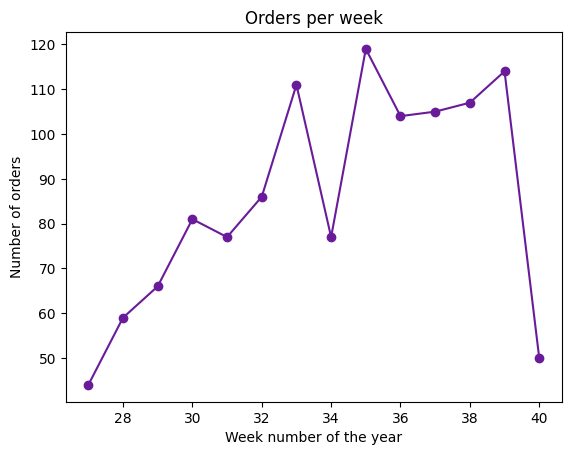

In [ ]:
weekly_orders = df.groupby("Week")["Order_ID"].count()

plt.plot(weekly_orders.index, weekly_orders.values, marker="o", color="#6A1B9A")
plt.title("Orders per week")
plt.xlabel("Week number of the year")
plt.ylabel("Number of orders")
plt.show()

#which parts of the day builds the weekly sale

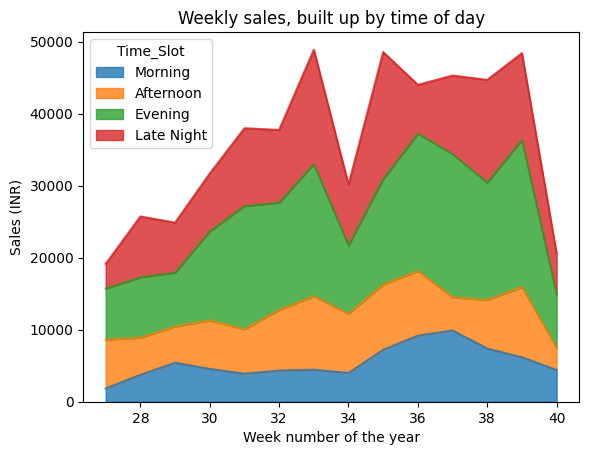

In [ ]:
week_slot = df.pivot_table(index="Week", columns="Time_Slot", values="Order_Value", aggfunc="sum")[slot_order]

week_slot.plot(kind="area", alpha=0.8)
plt.title("Weekly sales, built up by time of day")
plt.xlabel("Week number of the year")
plt.ylabel("Sales (INR)")
plt.show()


#Does a longer distance mean a slower delivery,and does a slower delivery mean a lower rating

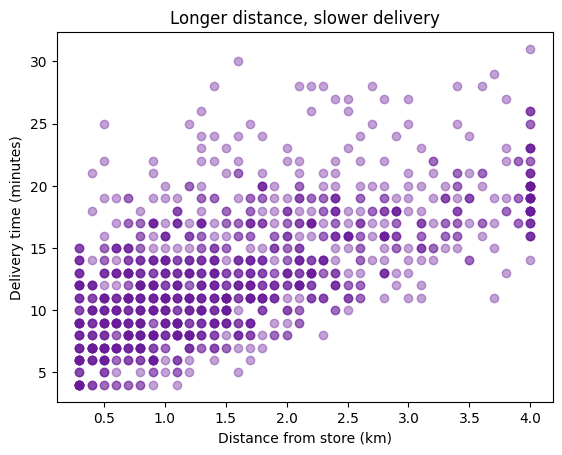

In [ ]:
plt.scatter(df["Distance_KM"], df["Delivery_Time_Min"], alpha=0.4, color="#6A1B9A")
plt.title("Longer distance, slower delivery")
plt.xlabel("Distance from store (km)")
plt.ylabel("Delivery time (minutes)")
plt.show()

#Quiver

In [ ]:
means = df.groupby(["State", "Weather"])[["Delivery_Time_Min", "Customer_Rating"]].mean().reset_index()

clear = means[means["Weather"] == "Clear"].set_index("State")
rain  = means[means["Weather"] == "Rain"].set_index("State")

x  = clear["Delivery_Time_Min"]                          # arrow starts here (clear weather)
y  = clear["Customer_Rating"]
dx = rain["Delivery_Time_Min"] - clear["Delivery_Time_Min"]   # how far rain moves it
dy = rain["Customer_Rating"] - clear["Customer_Rating"]

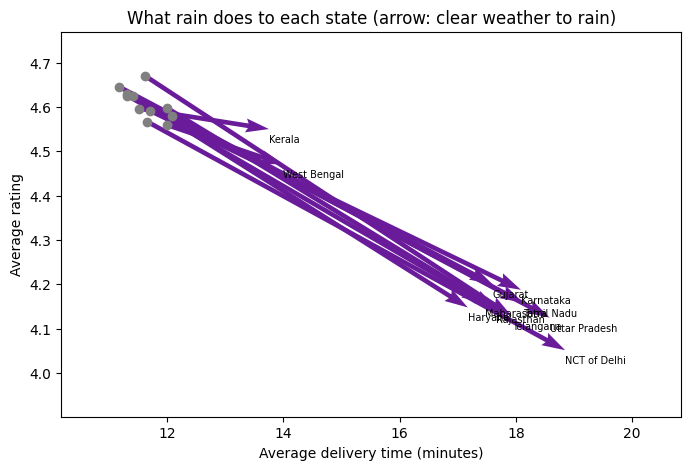

In [ ]:
plt.figure(figsize=(8, 5))
plt.quiver(x, y, dx, dy, angles="xy", scale_units="xy", scale=1, color="#6A1B9A")
plt.scatter(x, y, color="grey")

for name in clear.index:
    plt.text(x[name] + dx[name], y[name] + dy[name] - 0.03, name, fontsize=7)   # label at the arrow tip

plt.xlim(x.min() - 1, (x + dx).max() + 2)
plt.ylim((y + dy).min() - 0.15, y.max() + 0.1)
plt.title("What rain does to each state (arrow: clear weather to rain)")
plt.xlabel("Average delivery time (minutes)")
plt.ylabel("Average rating")
plt.show()

#Contour plots/2d plots

In [ ]:
# A tiny example first
distance = np.array([1, 2, 3])
basket   = np.array([5, 10])

D, B = np.meshgrid(distance, basket)

print(D)
print(B)

[[1 2 3]
 [1 2 3]]
[[ 5  5  5]
 [10 10 10]]


#Step 2 dividing matrix

In [ ]:
dist_values   = np.linspace(0.3, 4, 40)     # 40 distances, 0.3 to 4 km
basket_values = np.linspace(1, 12, 40)      # 40 basket sizes, 1 to 12 items

D, B = np.meshgrid(dist_values, basket_values)

print("Number of what-if cases:", D.size)

Number of what-if cases: 1600


#Step 3 linear regression - predictions

In [ ]:
# A simple formula from our data: delivery time from distance and basket size

from sklearn.linear_model import LinearRegression

formula = LinearRegression().fit(
    df[["Distance_KM", "Basket_Size"]],
    df["Delivery_Time_Min"]
)

print("Each extra km adds about", round(formula.coef_[0], 1), "minutes")
print("Each extra item adds about", round(formula.coef_[1], 2), "minutes")

Each extra km adds about 3.1 minutes
Each extra item adds about 0.31 minutes


#Step 4 what-ifcase

In [ ]:
# Fill every what-if case with the expected delivery time
cases = pd.DataFrame({
    "Distance_KM": D.ravel(),
    "Basket_Size": B.ravel()
})

T = formula.predict(cases).reshape(D.shape)

#how far can a store deliver for a giiven basket and still keep the 10 mins promise

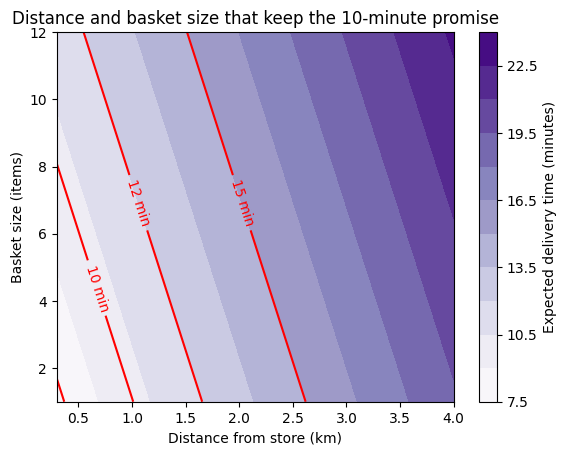

In [ ]:
plt.contourf(D, B, T, levels=10, cmap="Purples")
plt.colorbar(label="Expected delivery time (minutes)")

lines = plt.contour(D, B, T, levels=[8, 10, 12, 15], colors="red")
plt.clabel(lines, fmt="%d min")

plt.title("Distance and basket size that keep the 10-minute promise")
plt.xlabel("Distance from store (km)")
plt.ylabel("Basket size (items)")
plt.show()

#how did the same build up week by week

In [3]:
import pandas as pd
import numpy as np
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Ensure data and helper columns are loaded
df = pd.read_excel("Zepto_Orders_Data (1).xlsx", sheet_name="Orders")
df["Week"] = df["Order_Date"].dt.isocalendar().week.astype(int)

# Running total of sales, week by week, for each state
running = df.pivot_table(
    index='Week',
    columns='State',
    values='Order_Value',
    aggfunc='sum'
).fillna(0).cumsum()

running = running[running.iloc[-1].sort_values().index]  # smallest to largest

In [5]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, ax = plt.subplots(figsize=(7, 5))

def draw(i):
    ax.clear()
    # Use running.iloc[i] to animate frame-by-frame
    ax.barh(running.columns, running.iloc[i] / 1000, color="#6A189A")
    ax.set_xlim(0, running.values.max() / 1000 * 1.1)
    ax.set_title("Sales up to week " + str(running.index[i]))
    ax.set_xlabel("Sales (INR thousand)")

animation = FuncAnimation(fig, draw, frames=len(running), interval=700)
plt.close()
HTML(animation.to_jshtml())

In [6]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))

def draw(i):
    ax.clear()
    # Use the frame index 'i' to display cumulative sales up to that frame's week
    ax.barh(running.columns, running.iloc[i] / 1000, color="#6A189A")
    ax.set_xlim(0, running.values.max() / 1000 * 1.1)
    ax.set_title("Sales up to week " + str(running.index[i]))
    ax.set_xlabel("Sales (INR thousand)")

animation = FuncAnimation(fig, draw, frames=len(running), interval=700)

plt.close()
HTML(animation.to_jshtml())

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))

def draw(i):
    ax.clear()
    ax.barh(running.columns, running.iloc[1] / 1000, color="#6A189A")
    ax.set_xlim(0, running.values.max() / 1000* 1.1)
    ax. set_title("Sales up to week"+ str(running.index[i]))
    ax. set_xlabel("Sales (INR thousand)")

animation = FuncAnimation(fig, draw, frames=len(running), interval=700)

plt.close()                     # hide the extra still picture
HTML (animation.to_jshtml())    # press the play button

#WHAT TIME OF THE DAY GET MORE ORDER

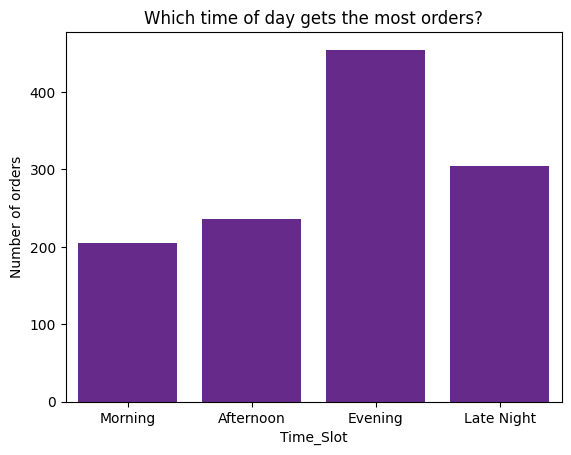

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define slot_order locally so the cell runs independently
slot_order = ["Morning", "Afternoon", "Evening", "Late Night"]

sns.countplot(
    data=df,
    x="Time_Slot",
    order=slot_order,
    color="#6A1B9A"
)

plt.title("Which time of day gets the most orders?")
plt.ylabel("Number of orders")
plt.show()

#WHICH PLOT IS THE BUSIEST PLOT

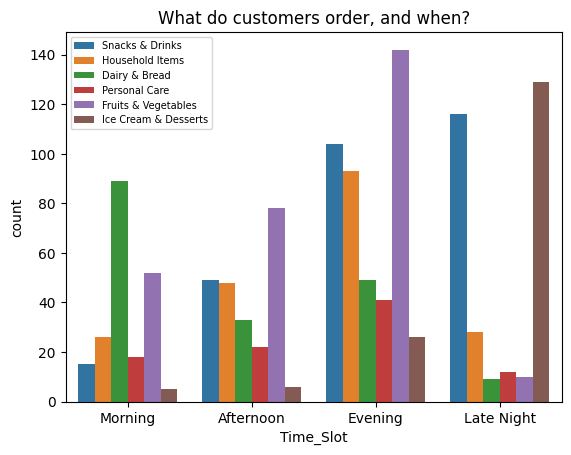

In [11]:
sns.countplot(
    data=df,
    x="Time_Slot",
    order=slot_order,
    hue="Category"
)

plt.title("What do customers order, and when?")
plt.legend(fontsize=7)
plt.show()

#WHICH TIME SLOT HAS THE SLOWEST AND LEAST PREDICTABLE DELIVERY

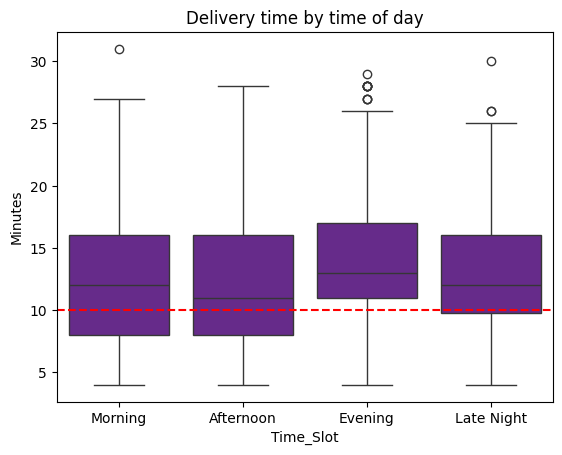

In [12]:
sns.boxplot(
    data=df,
    x="Time_Slot",
    y="Delivery_Time_Min",
    order=slot_order,
    color="#6A1B9A"
)

plt.axhline(10, color="red", linestyle="--")

plt.title("Delivery time by time of day")
plt.ylabel("Minutes")
plt.show()

#DO PASS MEMBERS SPEND DIFFRENTLY FROM NEW USERS

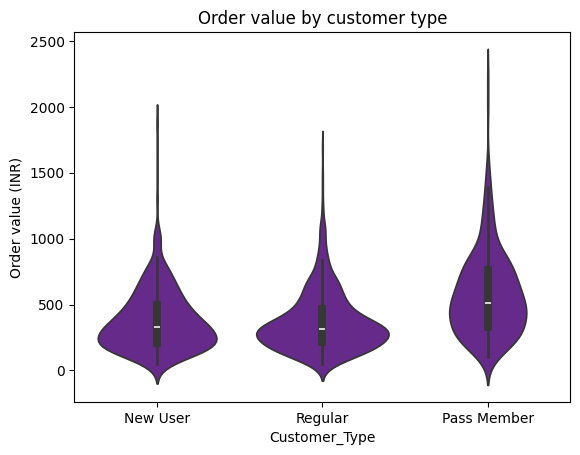

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define type_order locally so the cell runs independently
type_order = ["New User", "Regular", "Pass Member"]

sns.violinplot(
    data=df,
    x="Customer_Type",
    y="Order_Value",
    order=type_order,
    color="#6A1B9A"
)

plt.title("Order value by customer type")
plt.ylabel("Order value (INR)")
plt.show()

#ARE LOW RATING CAUSED BY MANY ORDERS OR ONLY A FEW-STRIP PLOT BY SEA BORN

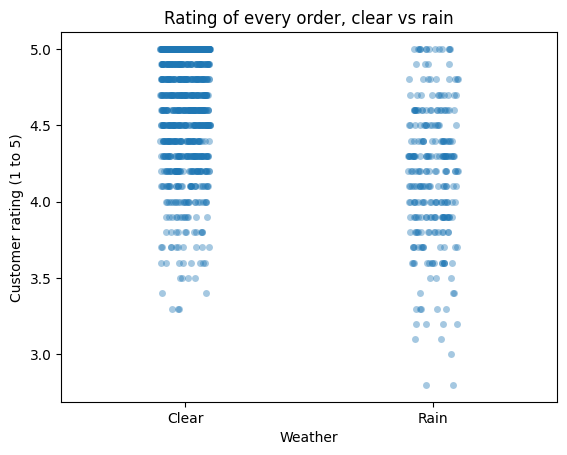

In [15]:
sns.stripplot(
    data=df,
    x="Weather",
    y="Customer_Rating",
    jitter=True,
    alpha=0.4
)

plt.title("Rating of every order, clear vs rain")
plt.ylabel("Customer rating (1 to 5)")
plt.show()

#do pass members really buy bigger basket

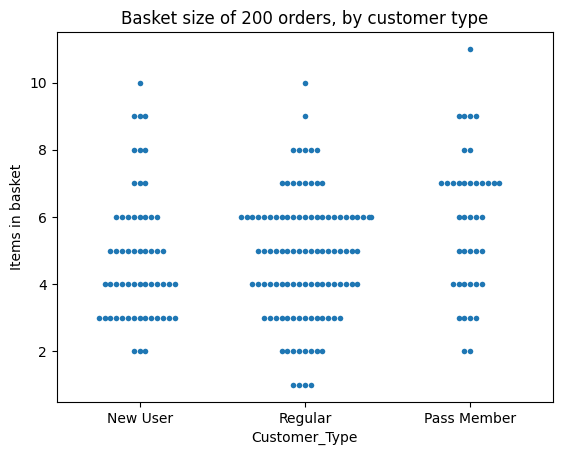

In [16]:
sample = df.sample(200, random_state=1)

sns.swarmplot(
    data=sample,
    x="Customer_Type",
    y="Basket_Size",
    order=type_order,
    size=4
)

plt.title("Basket size of 200 orders, by customer type")
plt.ylabel("Items in basket")
plt.show()